In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_parquet("../data/train.parquet")

print("Training dataset shape:", train_df.shape)

Training dataset shape: (58516, 45)


In [34]:
for column in train_df.columns:
    print(f"\n--- {column} ---")
    print("Data type:", train_df[column].dtype)

    try:
        print("Unique values:", train_df[column].nunique())
    except TypeError:
        print("Unique values: Cannot calculate directly (list/array data)")

    print("Missing values:", train_df[column].isna().sum())
    print("Example values:")
    print(train_df[column].head(5).tolist())


--- appID ---
Data type: str
Unique values: 58516
Missing values: 0
Example values:
['2888030', '753420', '747360', '2463530', '1269540']

--- name ---
Data type: str
Unique values: 58189
Missing values: 0
Example values:
['Coyote: An Old West Vignette', 'Dungreed', 'Gray Dawn', "Vacation Paradise: Florida Collector's Edition", 'Slash Roll']

--- release_date ---
Data type: datetime64[us]
Unique values: 4378
Missing values: 0
Example values:
[Timestamp('2024-05-30 00:00:00'), Timestamp('2018-02-14 00:00:00'), Timestamp('2018-06-07 00:00:00'), Timestamp('2023-07-22 00:00:00'), Timestamp('2020-08-26 00:00:00')]

--- estimated_owners ---
Data type: str
Unique values: 14
Missing values: 0
Example values:
['0 - 0', '200000 - 500000', '50000 - 100000', '0 - 20000', '0 - 20000']

--- peak_ccu ---
Data type: int64
Unique values: 749
Missing values: 0
Example values:
[0, 123, 1, 1, 0]

--- required_age ---
Data type: int64
Unique values: 12
Missing values: 0
Example values:
[0, 0, 0, 0, 0]

--

In [35]:
for column in train_df.columns:
    series = train_df[column]

    empty_strings = series.apply(
        lambda x: isinstance(x, str) and x.strip() == ""
    ).sum()

    empty_arrays = series.apply(
        lambda x: isinstance(x, (list, np.ndarray)) and len(x) == 0
    ).sum()

    if empty_strings > 0 or empty_arrays > 0:
        print(f"\n{column}")
        print("Empty strings:", empty_strings)
        print("Empty arrays:", empty_arrays)


name
Empty strings: 1
Empty arrays: 0

detailed_description
Empty strings: 3084
Empty arrays: 0

short_description
Empty strings: 3026
Empty arrays: 0

supported_languages
Empty strings: 0
Empty arrays: 3071

full_audio_languages
Empty strings: 0
Empty arrays: 34165

reviews
Empty strings: 51930
Empty arrays: 0

header_image
Empty strings: 45
Empty arrays: 0

website
Empty strings: 32872
Empty arrays: 0

support_url
Empty strings: 31130
Empty arrays: 0

support_email
Empty strings: 9890
Empty arrays: 0

metacritic_url
Empty strings: 56098
Empty arrays: 0

score_rank
Empty strings: 58492
Empty arrays: 0

notes
Empty strings: 48191
Empty arrays: 0

developers
Empty strings: 0
Empty arrays: 3101

publishers
Empty strings: 0
Empty arrays: 3313

categories
Empty strings: 0
Empty arrays: 3351

genres
Empty strings: 0
Empty arrays: 3074

tags
Empty strings: 0
Empty arrays: 58516

screenshots
Empty strings: 0
Empty arrays: 1888

movies
Empty strings: 0
Empty arrays: 58516


In [36]:
numeric_columns = train_df.select_dtypes(include="number").columns

for column in numeric_columns:
    zero_count = (train_df[column] == 0).sum()

    if zero_count > 0:
        print(f"{column}: {zero_count} zeros")

peak_ccu: 48036 zeros
required_age: 57805 zeros
price: 11837 zeros
dlc_count: 49420 zeros
metacritic_score: 56098 zeros
user_score: 58492 zeros
positive: 13675 zeros
negative: 20269 zeros
achievements: 28241 zeros
recommendations: 47546 zeros
average_playtime_forever: 44186 zeros
average_playtime_2weeks: 56623 zeros
median_playtime_forever: 44186 zeros
median_playtime_2weeks: 56623 zeros
hit: 43988 zeros


In [37]:
train_df.describe().T

,count,mean,min,25%,50%,75%,max,std
release_date,58516,2021-03-06 03:54:19.416228,2006-02-07 00:00:00,2019-02-20 00:00:00,2021-11-07 00:00:00,2023-09-22 00:00:00,2024-12-31 00:00:00,NaN
peak_ccu,58516.0,49.830713,0.0,0.0,0.0,0.0,623941.0,2779.268368
required_age,58516.0,0.196237,0.0,0.0,0.0,0.0,18.0,1.786549
price,58516.0,4.665838,0.0,0.59,1.99,4.99,999.98,13.532143
dlc_count,58516.0,0.640714,0.0,0.0,0.0,0.0,3703.0,17.495939
metacritic_score,58516.0,3.044706,0.0,0.0,0.0,0.0,97.0,14.812663
user_score,58516.0,0.031273,0.0,0.0,0.0,0.0,100.0,1.586411
positive,58516.0,1212.044689,0.0,1.0,9.0,55.0,2037143.0,21054.227704
negative,58516.0,179.325005,0.0,0.0,2.0,16.0,461826.0,3163.670872
achievements,58516.0,18.668569,0.0,0.0,3.0,19.0,5394.0,142.45069


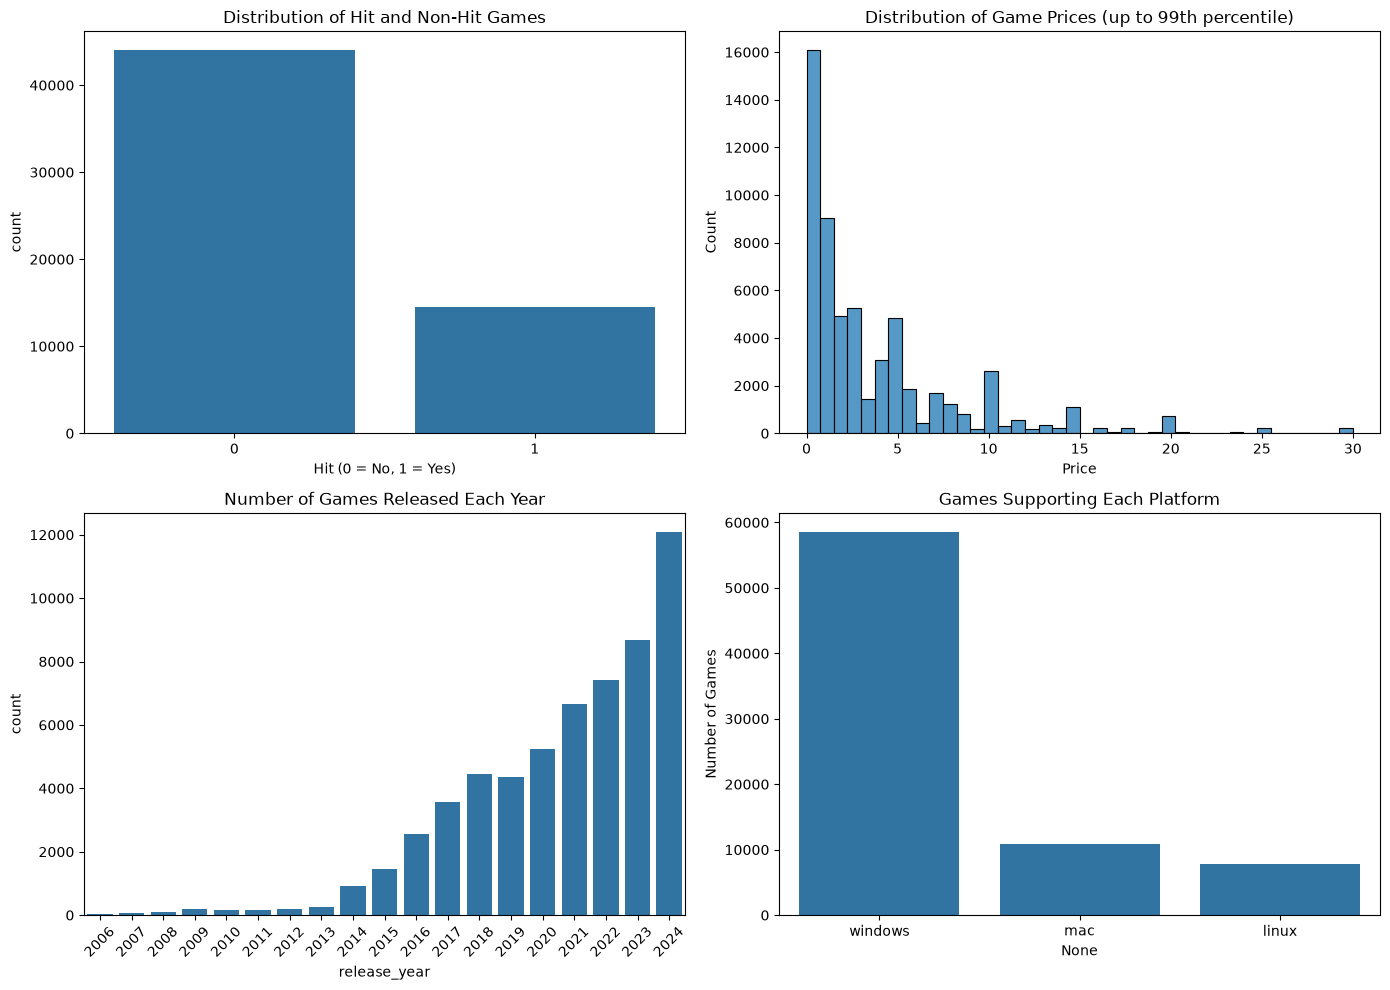

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribution of the target variable
sns.countplot(data=train_df, x="hit", ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Hit and Non-Hit Games")
axes[0, 0].set_xlabel("Hit (0 = No, 1 = Yes)")

# 2. Distribution of game prices
price_limit = train_df["price"].quantile(0.99)

sns.histplot(
    data=train_df[train_df["price"] <= price_limit],
    x="price",
    bins=40,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Distribution of Game Prices (up to 99th percentile)")
axes[0, 1].set_xlabel("Price")

# 3. Games released each year
sns.countplot(data=train_df, x="release_year", ax=axes[1, 0])
axes[1, 0].set_title("Number of Games Released Each Year")
axes[1, 0].tick_params(axis="x", rotation=45)

# 4. Platform support
platform_counts = train_df[["windows", "mac", "linux"]].sum()

sns.barplot(
    x=platform_counts.index,
    y=platform_counts.values,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Games Supporting Each Platform")
axes[1, 1].set_ylabel("Number of Games")

plt.tight_layout()
plt.show()

In [39]:
# Compare numerical features between hit and non-hit games

columns_to_compare = [
    "price",
    "required_age",
    "dlc_count",
    "achievements",
    "positive",
    "negative",
    "peak_ccu",
    "recommendations"
]

train_df.groupby("hit")[columns_to_compare].median().T

hit,0,1
price,1.99,3.74
required_age,0.00,0.00
dlc_count,0.00,0.00
achievements,0.00,17.00
positive,4.00,199.00
negative,1.00,41.00
peak_ccu,0.00,1.00
recommendations,0.00,161.00


  Platform  Hit rate
0  Windows  0.248359
1      Mac  0.342633
2    Linux  0.321939


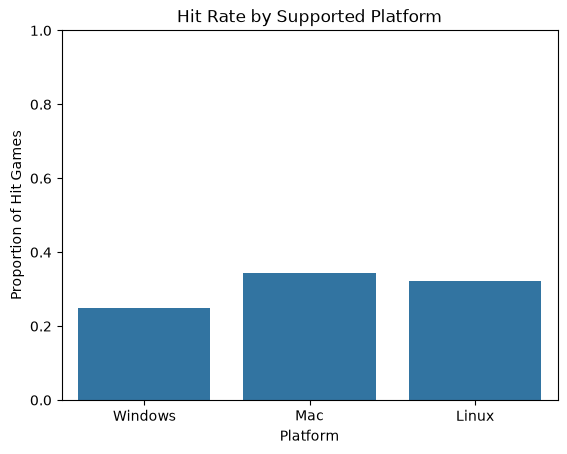

In [40]:
# Calculate the percentage of hit games for each platform

platform_hit_rates = pd.DataFrame({
    "Platform": ["Windows", "Mac", "Linux"],
    "Hit rate": [
        train_df.loc[train_df["windows"] == True, "hit"].mean(),
        train_df.loc[train_df["mac"] == True, "hit"].mean(),
        train_df.loc[train_df["linux"] == True, "hit"].mean()
    ]
})

print(platform_hit_rates)

# Visualise the results
sns.barplot(
    data=platform_hit_rates,
    x="Platform",
    y="Hit rate"
)

plt.title("Hit Rate by Supported Platform")
plt.ylabel("Proportion of Hit Games")
plt.ylim(0, 1)
plt.show()

### Platform support and game success

The hit rate is higher for games supporting Mac (34.26%) and Linux (32.19%) compared to Windows (24.84%).

This suggests that platform support may be related to game success. However, this does not prove that supporting Mac or Linux causes higher success. Other factors may influence these results.

Platform support is information that can generally be known before a game is released, so Windows, Mac and Linux can be considered valid potential features.

In [41]:
# Check minimum and maximum values of numerical columns

numeric_columns = train_df.select_dtypes(include="number").columns

for column in numeric_columns:
    print(f"{column}: min = {train_df[column].min()}, max = {train_df[column].max()}")

peak_ccu: min = 0, max = 623941
required_age: min = 0, max = 18
price: min = 0.0, max = 999.98
dlc_count: min = 0, max = 3703
metacritic_score: min = 0, max = 97
user_score: min = 0, max = 100
positive: min = 0, max = 2037143
negative: min = 0, max = 461826
achievements: min = 0, max = 5394
recommendations: min = 0, max = 1854262
average_playtime_forever: min = 0, max = 3429544
average_playtime_2weeks: min = 0, max = 20088
median_playtime_forever: min = 0, max = 3429544
median_playtime_2weeks: min = 0, max = 20088
release_year: min = 2006, max = 2024
rank_in_year: min = 1.0, max = 20031.0
games_in_year: min = 69, max = 20031
hit: min = 0, max = 1


In [42]:
# Inspect the 10 most expensive games

train_df[["name", "price", "hit", "release_year"]].sort_values(
    by="price",
    ascending=False
).head(10)

,name,price,hit,release_year
15781,The Leverage Game Business Edition,999.98,0,2023
53382,The Leverage Game,999.98,0,2023
44251,Ascent Free-Roaming VR Experience,999.00,0,2019
45819,True Love,500.00,0,2024
19641,Houdini Indie,269.99,1,2018
23437,Hidden Town,199.99,0,2021
51125,Save Scream and Run,199.99,0,2024
50787,Hidden Ghost Town,199.99,0,2023
57008,Charades Movie One,199.99,0,2023
29607,Hidden Islands,199.99,0,2023


### Investigation of unusually high prices

The 10 most expensive games were inspected. Some games have prices close to €1,000, which is unusually high compared to typical Steam games.

Most of these games are labelled as non-hits, although there are some exceptions. These prices may belong to specialised software or unusual products rather than ordinary games.

The values are not automatically considered errors, so the rows will be kept. However, extreme prices may affect the model and should be considered when evaluating whether price is a suitable feature for pre-release predictions.

In [43]:
# Inspect the 10 games with the highest average lifetime playtime

train_df[
    ["name", "average_playtime_forever", "hit", "release_year"]
].sort_values(
    by="average_playtime_forever",
    ascending=False
).head(10)

,name,average_playtime_forever,hit,release_year
7855,Avem33,3429544,0,2017
54307,iTownGamePlay UNIVERSE,1714275,0,2017
49035,Letters From a Rainy Day -Oceans and Lace-,359665,1,2021
49477,爱人 Lover,322983,1,2021
28094,KAMI,196736,1,2014
38895,秘密舞会,189436,1,2021
24238,Love Stories: When Pastel Meets Grotesque,158764,1,2022
13591,Franchise Hockey Manager 9,151767,1,2022
42664,The Red Stare,114327,1,2017
31285,Ai Vpet,106035,1,2024


### Investigation of unusually high playtime

The 10 games with the highest average lifetime playtime were inspected. Some values are extremely high, with the highest reaching 3,429,544 minutes.

These values may represent unusual player activity or possible data quality issues. However, there is not enough information to conclude that they are incorrect, so the rows will not be removed based only on these values.

Average lifetime playtime is a post-release statistic. It cannot be used to predict a game's success before release because it contains information collected after the game became available. Therefore, this column will be excluded from the prediction features to avoid data leakage.

In [44]:
# Calculate correlations between numerical columns

numeric_df = train_df.select_dtypes(include="number")

correlation = numeric_df.corr()

# Display correlations with the target variable
correlation["hit"].sort_values(ascending=False)

hit                         1.000000
metacritic_score            0.224795
required_age                0.102298
positive                    0.097952
recommendations             0.096940
negative                    0.092948
average_playtime_2weeks     0.071361
median_playtime_2weeks      0.070981
achievements                0.067365
price                       0.041612
dlc_count                   0.040706
peak_ccu                    0.030863
average_playtime_forever    0.012741
median_playtime_forever     0.008074
games_in_year               0.003394
release_year                0.002937
user_score                 -0.000532
rank_in_year               -0.543937
Name: hit, dtype: float64

### Correlation analysis

The correlation analysis shows that `metacritic_score` has the strongest positive correlation with `hit` (0.225). However, this information may be collected after release and should not be used for pre-release predictions.

The `rank_in_year` column has a strong negative correlation with `hit` (-0.544). This is expected because the hit target was created using review rankings within each release year. Since this column is directly related to how the target was created, it must be excluded to avoid target leakage.

Other columns, such as `positive`, `negative` and `recommendations`, have weak positive correlations with `hit`. However, they contain post-release information and cannot be used as pre-release prediction features.

`Price` has a weak positive correlation (0.042), but it will remain a potential feature. A weak individual correlation does not necessarily mean that a feature is useless in a machine learning model. However, it is important to consider whether the available price represents the price at the time of release.

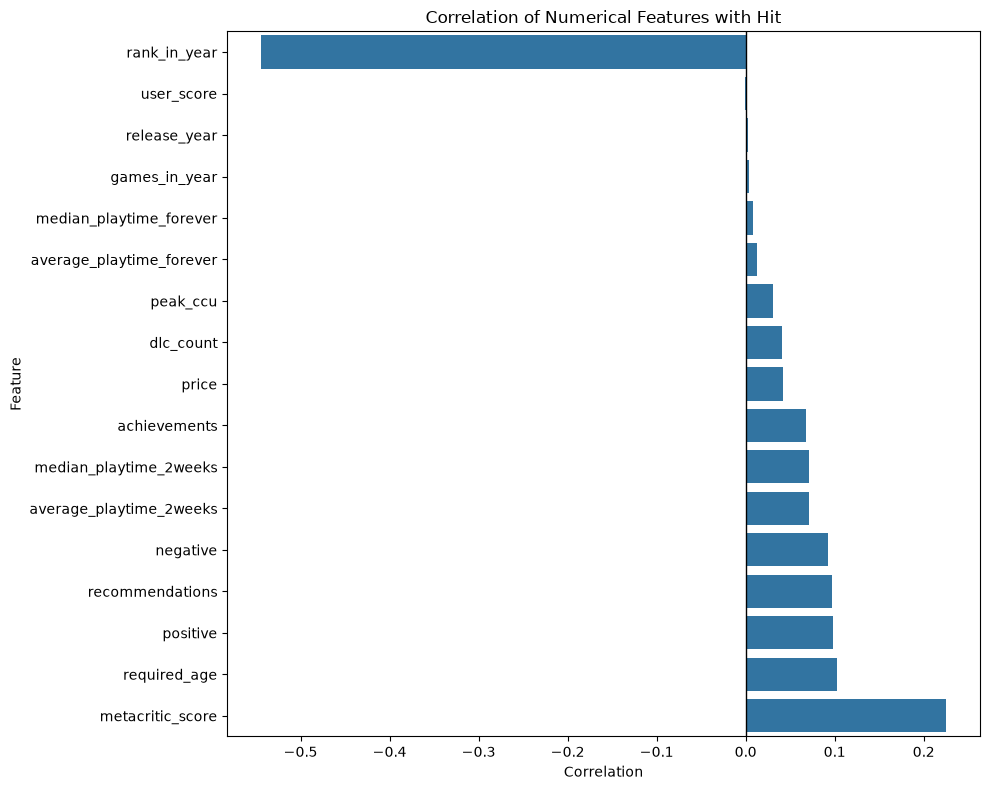

In [45]:
# Visualise correlations with the target variable

correlations_with_hit = correlation["hit"].drop("hit").sort_values()

plt.figure(figsize=(10, 8))

sns.barplot(
    x=correlations_with_hit.values,
    y=correlations_with_hit.index
)

plt.title("Correlation of Numerical Features with Hit")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

### Visualisation of numerical correlations

The correlation chart confirms the results from the correlation table.

`rank_in_year` has the strongest negative correlation with `hit`, approximately -0.55. This is expected because it was used to determine the target variable and must therefore be excluded to avoid target leakage.

`metacritic_score` has the strongest positive correlation, approximately 0.22. However, it may contain post-release information and will also be excluded from pre-release predictions.

`price` has a very weak positive correlation, but it will remain a potential feature. However, it is important to consider whether the available price represents the price at the time of release.

The correlation results help identify relationships, but feature selection will also consider data leakage and whether information is realistically available before a game is released.

In [46]:
# Review all columns and decide whether they can be used as features

feature_decisions = {
    "appID": "Exclude - game identifier",
    "name": "Grey area - could be used for text analysis",
    "release_date": "Keep - known before release",
    "estimated_owners": "Exclude - estimated after release",
    "peak_ccu": "Exclude - post-release player activity",
    "required_age": "Keep - age rating known before release",
    "price": "Grey area - current price may differ from launch price",
    "dlc_count": "Grey area - may change after release",
    "detailed_description": "Keep - potentially available before release",
    "short_description": "Keep - potentially available before release",
    "supported_languages": "Keep - potentially available before release",
    "full_audio_languages": "Keep - potentially available before release",
    "reviews": "Exclude - post-release information",
    "header_image": "Keep - potentially available before release",
    "website": "Keep - potentially available before release",
    "support_url": "Keep - potentially available before release",
    "support_email": "Keep - potentially available before release",
    "windows": "Keep - platform support",
    "mac": "Keep - platform support",
    "linux": "Keep - platform support",
    "metacritic_score": "Exclude - post-release review score",
    "metacritic_url": "Exclude - related to post-release reviews",
    "user_score": "Exclude - post-release score",
    "positive": "Exclude - used to create target",
    "negative": "Exclude - used to create target",
    "score_rank": "Exclude - based on reviews",
    "achievements": "Grey area - may change after release",
    "recommendations": "Exclude - post-release information",
    "notes": "Grey area - timing of information is unclear",
    "average_playtime_forever": "Exclude - post-release information",
    "average_playtime_2weeks": "Exclude - post-release information",
    "median_playtime_forever": "Exclude - post-release information",
    "median_playtime_2weeks": "Exclude - post-release information",
    "developers": "Keep - known before release",
    "publishers": "Keep - known before release",
    "categories": "Keep - potentially available before release",
    "genres": "Keep - potentially available before release",
    "tags": "Grey area - may include user-generated information",
    "screenshots": "Keep - potentially available before release",
    "movies": "Grey area - availability before release is unclear",
    "packages": "Grey area - package information may change",
    "release_year": "Exclude as a model feature - used only to create the year-relative hit target",
    "rank_in_year": "Exclude - directly related to target creation",
    "games_in_year": "Grey area - depends on how it is calculated",
    "hit": "Target - not a feature"
}

decision_df = pd.DataFrame(
    list(feature_decisions.items()),
    columns=["Column", "Decision"]
)

decision_df

,Column,Decision
0,appID,Exclude - game identifier
1,name,Grey area - could be used for text analysis
2,release_date,Keep - known before release
3,estimated_owners,Exclude - estimated after release
4,peak_ccu,Exclude - post-release player activity
5,required_age,Keep - age rating known before release
6,price,Grey area - current price may differ from laun...
7,dlc_count,Grey area - may change after release
8,detailed_description,Keep - potentially available before release
9,short_description,Keep - potentially available before release


In [47]:
# Select the features used by the best M1 model

selected_features = [
    "price",
    "windows",
    "mac",
    "linux"
]

target = "hit"

X_train = train_df[selected_features].copy()
y_train = train_df[target].copy()

print("Selected features:", selected_features)
print("Training features shape:", X_train.shape)
print("Training target shape:", y_train.shape)

X_train.head()

Selected features: ['price', 'windows', 'mac', 'linux']
Training features shape: (58516, 4)
Training target shape: (58516,)


,price,windows,mac,linux
0,0.00,True,False,False
1,4.99,True,True,True
2,1.99,True,False,False
3,6.49,True,False,False
4,2.99,True,False,True


In [48]:
# Check missing values in the selected features
print("Missing values:")
print(X_train.isna().sum())

# Check price distribution
print("\nPrice statistics:")
print(X_train["price"].describe())

# Check unusually high and invalid prices
print("\nNegative prices:", (X_train["price"] < 0).sum())
print("Prices above €100:", (X_train["price"] > 100).sum())

# Check platform support distribution
for column in ["windows", "mac", "linux"]:
    print(f"\n{column} distribution:")
    print(X_train[column].value_counts())

Missing values:
price      0
windows    0
mac        0
linux      0
dtype: int64

Price statistics:
count    58516.000000
mean         4.665838
std         13.532143
min          0.000000
25%          0.590000
50%          1.990000
75%          4.990000
max        999.980000
Name: price, dtype: float64

Negative prices: 0
Prices above €100: 148

windows distribution:
windows
True     58496
False       20
Name: count, dtype: int64

mac distribution:
mac
False    47691
True     10825
Name: count, dtype: int64

linux distribution:
linux
False    50676
True      7840
Name: count, dtype: int64


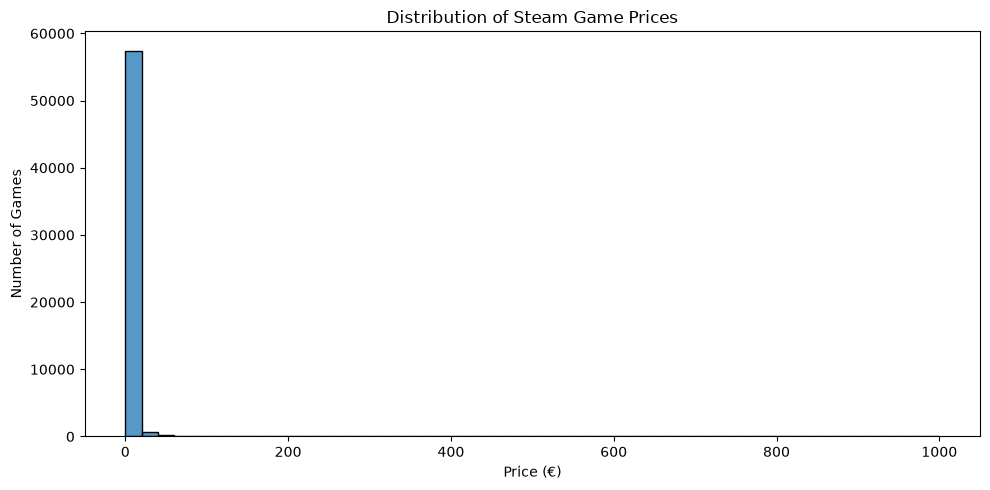

Games priced above €100: 148


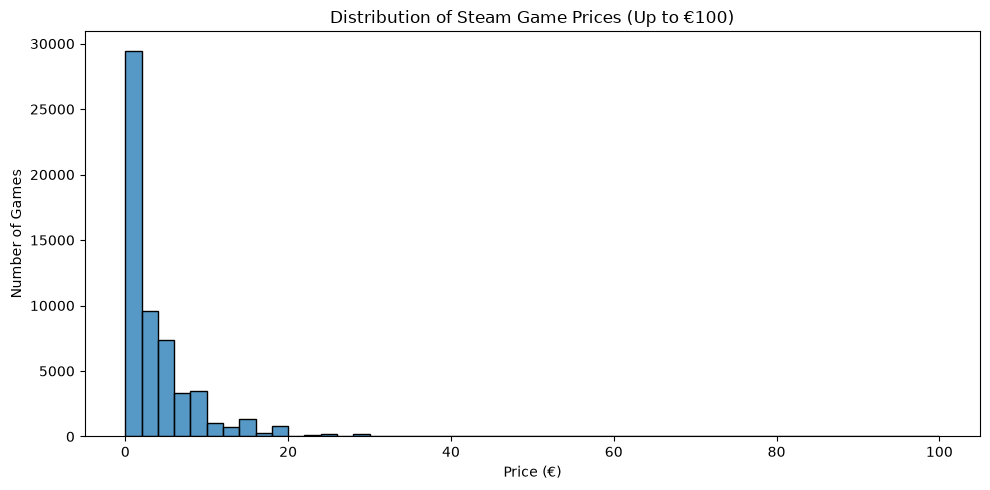

In [49]:
# Examine the distribution of game prices

plt.figure(figsize=(10, 5))

sns.histplot(train_df["price"], bins=50)

plt.title("Distribution of Steam Game Prices")
plt.xlabel("Price (€)")
plt.ylabel("Number of Games")

plt.tight_layout()
plt.show()


# Count games above €100
print("Games priced above €100:", (train_df["price"] > 100).sum())

# Show the price distribution without extreme prices
plt.figure(figsize=(10, 5))

sns.histplot(
    train_df.loc[train_df["price"] <= 100, "price"],
    bins=50
)

plt.title("Distribution of Steam Game Prices (Up to €100)")
plt.xlabel("Price (€)")
plt.ylabel("Number of Games")

plt.tight_layout()
plt.show()

### Price distribution

The price distribution is heavily right-skewed. Most games are priced below €20, and many games are free or very inexpensive.

The median price is €1.99, while the maximum price is €999.98. There are 148 games priced above €100. These extreme values make the full price distribution difficult to examine using a normal linear scale.

A logarithmic scale could make the distribution easier to visualize. However, the high prices should not automatically be removed because they may represent legitimate products.

For now, I will keep the original price values because there is no clear evidence that the high prices are incorrect. I will consider whether price is a suitable feature when evaluating which information would realistically be available before a game is released.

In [50]:
# Check platform support combinations

platform_columns = ["windows", "mac", "linux"]

print("Games supporting no platforms:")
print((~train_df[platform_columns]).all(axis=1).sum())

print("\nPlatform combinations:")
print(
    train_df.groupby(platform_columns, observed=True)
    .size()
    .sort_values(ascending=False)
)

Games supporting no platforms:
0

Platform combinations:
windows  mac    linux
True     False  False    45621
         True   True      5770
                False     5044
         False  True      2061
False    True   False       11
         False  True         9
dtype: int64


### Platform support combinations

All games in the training dataset support at least one of the three platforms.

Most games (45,621) support only Windows. A smaller number support multiple platforms, and 20 games support Mac or Linux without supporting Windows.

The platform columns contain valid boolean values and no missing data. Therefore, no cleaning is necessary for these columns.

In [51]:
# Compare average hit rates by platform support

for platform in ["windows", "mac", "linux"]:
    print(f"\n{platform.upper()} support:")
    print(
        train_df.groupby(platform, observed=True)["hit"]
        .agg(["count", "mean"])
    )

print("\nAverage hit rate by price group:")

train_df["price_group"] = pd.cut(
    train_df["price"],
    bins=[-0.01, 0, 5, 10, 20, 50, 100, float("inf")],
    labels=[
        "Free",
        "0.01-5",
        "5-10",
        "10-20",
        "20-50",
        "50-100",
        "Above 100"
    ]
)

print(
    train_df.groupby("price_group", observed=True)["hit"]
    .agg(["count", "mean"])
)


WINDOWS support:
         count      mean
windows                 
False       20  0.000000
True     58496  0.248359

MAC support:
       count      mean
mac                   
False  47691  0.226856
True   10825  0.342633

LINUX support:
       count      mean
linux                 
False  50676  0.236877
True    7840  0.321939

Average hit rate by price group:
             count      mean
price_group                 
Free         11837  0.156712
0.01-5       32596  0.229998
5-10          8842  0.339064
10-20         4169  0.426241
20-50          795  0.461635
50-100         129  0.248062
Above 100      148  0.013514


### Relationship between price, platforms and game success

Games supporting Mac and Linux have higher hit rates than games without support for these platforms. Mac-supported games have a hit rate of 34.26%, while Linux-supported games have a hit rate of 32.19%.

The price analysis shows that hit rates generally increase with price up to the €20-50 range. However, games priced above €100 have a very low hit rate of 1.35%.

These results show associations between the features and game success, but they do not prove causation. Some price groups also contain relatively few games.

Windows support has limited variation because almost all games support Windows.

In [52]:
# Check the price distribution using percentiles

print("Price percentiles:")
print(
    train_df["price"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00]
    )
)

print("\nNumber of games above selected price limits:")

for limit in [20, 50, 100, 200]:
    count = (train_df["price"] > limit).sum()
    print(f"Above €{limit}: {count}")

Price percentiles:
0.500      1.99
0.750      4.99
0.900      9.99
0.950     14.99
0.990     29.99
0.995     49.99
1.000    999.98
Name: price, dtype: float64

Number of games above selected price limits:
Above €20: 1072
Above €50: 277
Above €100: 148
Above €200: 5


### Price outliers and data quality

The price distribution confirms that most Steam games are relatively inexpensive. The median price is €1.99, and 99% of games cost €29.99 or less.

Only 277 games cost more than €50, and only five cost more than €200. These values are unusual but cannot automatically be considered errors.

I decided to keep the original price values instead of removing or changing expensive games. The M1 model uses StandardScaler, which standardizes the numerical price feature before training.

In [53]:
# Check data types and missing values in the training dataset

data_quality = pd.DataFrame({
    "Data type": train_df.dtypes.astype(str),
    "Missing values": train_df.isna().sum()
})

unique_counts = []

for column in train_df.columns:
    try:
        unique_counts.append(train_df[column].nunique())
    except TypeError:
        unique_counts.append("Contains arrays")

data_quality["Unique values"] = unique_counts

data_quality

,Data type,Missing values,Unique values
appID,str,0,58516
name,str,0,58189
release_date,datetime64[us],0,4378
estimated_owners,str,0,14
peak_ccu,int64,0,749
required_age,int64,0,12
price,float64,0,675
dlc_count,int64,0,94
detailed_description,str,0,55194
short_description,str,0,54970


### Data types and missing values

The dataset contains no pandas missing values in its original columns. However, several columns contain empty strings or empty arrays, which represent unavailable information.

The numerical columns have appropriate numerical data types, and the platform columns use boolean values. The target column, hit, contains two unique values (0 and 1), making it suitable for binary classification.

Several columns contain arrays, such as genres, categories, developers and supported languages. These would need additional processing before they could be used directly in a machine learning model.

The additional price_group column was created for exploratory analysis and will not be included in the original M1 model.

In [54]:
# Load the original validation and test datasets

val_df = pd.read_parquet("../data/validation.parquet")
test_df = pd.read_parquet("../data/test.parquet")

# Verify the original data split

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Training: 58516
Validation: 19506
Test: 19506

Total: 97528


### Verification of the original data split

The original data split has been preserved:

- Training: 58,516 rows
- Validation: 19,506 rows
- Test: 19,506 rows

The datasets have the same sizes as in M1. This allows a fair comparison between the original model and the model developed after data quality analysis.

In [55]:
# Select the features used by the best M1 model

selected_features = [
    "price",
    "windows",
    "mac",
    "linux"
]

target = "hit"

# Prepare training, validation and test data

X_train = train_df[selected_features].copy()
y_train = train_df[target].copy()

X_val = val_df[selected_features].copy()
y_val = val_df[target].copy()

X_test = test_df[selected_features].copy()
y_test = test_df[target].copy()

# Check the prepared datasets

print("Selected features:", selected_features)
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

Selected features: ['price', 'windows', 'mac', 'linux']
Training features: (58516, 4)
Validation features: (19506, 4)
Test features: (19506, 4)


In [56]:
# Retrain the original M1 model

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

m1_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train using the training dataset
m1_model.fit(X_train, y_train)

# Evaluate using the validation dataset
y_val_pred = m1_model.predict(X_val)

print("M1 model - Validation results")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 3))
print("Precision:", round(precision_score(y_val, y_val_pred), 3))
print("Recall:", round(recall_score(y_val, y_val_pred), 3))
print("F1-score:", round(f1_score(y_val, y_val_pred), 3))

M1 model - Validation results
--------------------------------
Accuracy: 0.677
Precision: 0.356
Recall: 0.351
F1-score: 0.353


### Reproducing the M1 baseline model

I retrained the best model from M1 using the same four features: price, Windows, Mac and Linux support.

The model uses StandardScaler and Logistic Regression with class_weight="balanced".

The validation results are identical to those obtained in M1:

- Accuracy: 67.7%
- Precision: 35.6%
- Recall: 35.1%
- F1-score: 35.3%

This confirms that the original model has been reproduced successfully. These results will be used as the baseline when comparing changes made during M2.

In [57]:
# Check for invalid or unusual price values

print("Missing prices:", train_df["price"].isna().sum())
print("Negative prices:", (train_df["price"] < 0).sum())
print("Zero-price games:", (train_df["price"] == 0).sum())
print("Prices above €100:", (train_df["price"] > 100).sum())

print("\nHighest 10 prices:")
print(
    train_df[["name", "price"]]
    .sort_values("price", ascending=False)
    .head(10)
)

Missing prices: 0
Negative prices: 0
Zero-price games: 11837
Prices above €100: 148

Highest 10 prices:
                                     name   price
15781  The Leverage Game Business Edition  999.98
53382                   The Leverage Game  999.98
44251   Ascent Free-Roaming VR Experience  999.00
45819                           True Love  500.00
19641                       Houdini Indie  269.99
23437                         Hidden Town  199.99
51125                 Save Scream and Run  199.99
50787                   Hidden Ghost Town  199.99
57008                  Charades Movie One  199.99
29607                      Hidden Islands  199.99


### Price data quality decisions

The price column contains no missing values or negative prices. There are 11,837 games with a price of zero, which can represent free-to-play games.

There are also 148 games priced above €100. Although these values are unusually high, they may represent legitimate products.

I decided to keep all original price values because there is no clear evidence that they are incorrect. Removing these values could result in losing valid information.

One limitation is that the dataset contains current prices, which may differ from the original launch prices. Therefore, price is a potential feature, but its availability before release is uncertain.

In [58]:
# Check the selected features

print("Feature data types:")
print(train_df[selected_features].dtypes)

print("\nMissing values:")
print(train_df[selected_features].isna().sum())

print("\nFeature summary:")
print(train_df[selected_features].describe(include="all"))

Feature data types:
price      float64
windows       bool
mac           bool
linux         bool
dtype: object

Missing values:
price      0
windows    0
mac        0
linux      0
dtype: int64

Feature summary:
               price windows    mac  linux
count   58516.000000   58516  58516  58516
unique           NaN       2      2      2
top              NaN    True  False  False
freq             NaN   58496  47691  50676
mean        4.665838     NaN    NaN    NaN
std        13.532143     NaN    NaN    NaN
min         0.000000     NaN    NaN    NaN
25%         0.590000     NaN    NaN    NaN
50%         1.990000     NaN    NaN    NaN
75%         4.990000     NaN    NaN    NaN
max       999.980000     NaN    NaN    NaN


### Selected feature data quality

The four selected features have appropriate data types for machine learning.

The price column uses a numerical data type, while Windows, Mac and Linux use Boolean values.

None of the selected features contain missing values in the training dataset. The platform columns also contain valid True/False values.

Therefore, no additional data cleaning or type conversion is necessary for these features.

In [59]:
# Final feature selection for the M2 model

m2_features = [
    "price",
    "windows",
    "mac",
    "linux"
]

# Check the selected features
print("M2 selected features:")
for feature in m2_features:
    print("-", feature)

print("\nNumber of selected features:", len(m2_features))

M2 selected features:
- price
- windows
- mac
- linux

Number of selected features: 4


### Final feature selection

For the M2 model, I decided to keep the same four features used in M1:

- **price:** Numerical feature. Its availability before release is uncertain because the dataset may contain current prices rather than launch prices.
- **windows:** Boolean feature indicating Windows support.
- **mac:** Boolean feature indicating Mac support.
- **linux:** Boolean feature indicating Linux support.

The platform support information can generally be known before release. Price is retained to allow a direct comparison with M1, but it has a limitation regarding prediction timing.

All features used in the model are available in the training, validation and test datasets.

Columns containing post-release information, such as positive reviews, negative reviews, recommendations and playtime, are excluded to avoid data leakage.

In [60]:
# Prepare the M2 datasets using the final feature selection

X_train_m2 = train_df[m2_features].copy()
X_val_m2 = val_df[m2_features].copy()
X_test_m2 = test_df[m2_features].copy()

y_train_m2 = train_df["hit"].copy()
y_val_m2 = val_df["hit"].copy()
y_test_m2 = test_df["hit"].copy()

print("Training:", X_train_m2.shape)
print("Validation:", X_val_m2.shape)
print("Test:", X_test_m2.shape)

Training: (58516, 4)
Validation: (19506, 4)
Test: (19506, 4)


In [61]:
# Train the M2 Logistic Regression model

m2_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

m2_model.fit(X_train_m2, y_train_m2)

# Evaluate on validation data
y_val_m2_pred = m2_model.predict(X_val_m2)

print("M2 model - Validation results")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_val_m2, y_val_m2_pred), 3))
print("Precision:", round(precision_score(y_val_m2, y_val_m2_pred), 3))
print("Recall:", round(recall_score(y_val_m2, y_val_m2_pred), 3))
print("F1-score:", round(f1_score(y_val_m2, y_val_m2_pred), 3))

M2 model - Validation results
--------------------------------
Accuracy: 0.677
Precision: 0.356
Recall: 0.351
F1-score: 0.353


### M1 and M2 model comparison

The M2 model produced exactly the same validation results as the M1 model.

Both models achieved:
- Accuracy: 67.7%
- Precision: 35.6%
- Recall: 35.1%
- F1-score: 35.3%

This result was expected because the same four features, training data, data split and Logistic Regression settings were used.

The data quality investigation did not identify clear errors in the four selected features that justified changing their values.

Therefore, no value-level corrections were necessary for the selected features, and the original train, validation and test datasets were preserved

However, the analysis identified an important limitation: the current price may not represent the launch price. Therefore, the model cannot guarantee that all selected features would have been available before release.

Further feature engineering may improve the model, but the baseline comparison confirms that the M1 results are reproducible.

In [62]:
# Create a model using only platform support features

strict_features = [
    "windows",
    "mac",
    "linux"
]

X_train_strict = train_df[strict_features].copy()
X_val_strict = val_df[strict_features].copy()

# Train the Logistic Regression model

strict_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

strict_model.fit(X_train_strict, y_train)

# Evaluate on validation data

y_val_strict_pred = strict_model.predict(X_val_strict)

print("Strict pre-release model - Validation results")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_strict_pred), 3))
print("Precision:", round(precision_score(y_val, y_val_strict_pred), 3))
print("Recall:", round(recall_score(y_val, y_val_strict_pred), 3))
print("F1-score:", round(f1_score(y_val, y_val_strict_pred), 3))

Strict pre-release model - Validation results
--------------------------------
Accuracy: 0.687
Precision: 0.333
Recall: 0.243
F1-score: 0.281


### Strict pre-release model comparison

I trained an additional model using only Windows, Mac and Linux support, excluding price because its availability before release is uncertain.

The strict model achieved:
- Accuracy: 68.7%
- Precision: 33.3%
- Recall: 24.3%
- F1-score: 28.1%

Compared with M1 and M2, accuracy increased slightly, but precision, recall and F1-score decreased.

This suggests that price provides useful predictive information to the original model. However, excluding price makes the strict model more suitable for a prediction made before release.

The results show a trade-off between predictive performance and the availability of information at prediction time.

In [63]:
# Compare the three models on validation data

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "M1 baseline": [
        accuracy_score(y_val, y_val_pred),
        precision_score(y_val, y_val_pred),
        recall_score(y_val, y_val_pred),
        f1_score(y_val, y_val_pred)
    ],
    "M2 model": [
        accuracy_score(y_val_m2, y_val_m2_pred),
        precision_score(y_val_m2, y_val_m2_pred),
        recall_score(y_val_m2, y_val_m2_pred),
        f1_score(y_val_m2, y_val_m2_pred)
    ],
    "Strict pre-release": [
        accuracy_score(y_val, y_val_strict_pred),
        precision_score(y_val, y_val_strict_pred),
        recall_score(y_val, y_val_strict_pred),
        f1_score(y_val, y_val_strict_pred)
    ]
})

comparison.round(3)

,Metric,M1 baseline,M2 model,Strict pre-release
0,Accuracy,0.677,0.677,0.687
1,Precision,0.356,0.356,0.333
2,Recall,0.351,0.351,0.243
3,F1-score,0.353,0.353,0.281


In [64]:
# Final evaluation of the strict pre-release model on test data

X_test_strict = test_df[strict_features].copy()

y_test_strict_pred = strict_model.predict(X_test_strict)

print("Strict pre-release model - Final test results")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_test_strict_pred), 3))
print("Precision:", round(precision_score(y_test, y_test_strict_pred), 3))
print("Recall:", round(recall_score(y_test, y_test_strict_pred), 3))
print("F1-score:", round(f1_score(y_test, y_test_strict_pred), 3))

Strict pre-release model - Final test results
--------------------------------
Accuracy: 0.689
Precision: 0.35
Recall: 0.263
F1-score: 0.3


### Final test evaluation

After completing the model comparison, I evaluated the strict pre-release model on the test dataset.

The final test results were:

- Accuracy: 68.9%
- Precision: 35.0%
- Recall: 26.3%
- F1-score: 30.0%

The results are slightly better than the validation results, suggesting that the model performs similarly on both datasets.

The strict model uses only Windows, Mac and Linux support. It excludes price because the dataset may contain current prices rather than launch prices.

Although the strict model has a higher accuracy than the original M1 model, its F1-score is lower. This means that it is less effective at identifying successful games.

The model provides a useful baseline for predicting Steam game success before release, but its predictive performance is still limited.

## M2 Conclusion: Getting to Know the Data

During M2, I investigated the Steam games dataset to understand its structure, data quality and relationship with game success.

The original dataset contains 41 columns. During data preparation, four additional columns were created: `release_year`, `rank_in_year`, `games_in_year`, and `hit`. This resulted in 45 columns in the prepared dataset, with 58,516 training rows. I examined the data types, missing values, empty strings, zero values, unusual numerical values and feature distributions.

### Data quality findings

- The original dataset contains no pandas missing values, but several columns contain empty strings or empty arrays.
- The price column is heavily right-skewed, with a median of €1.99 and a maximum of €999.98.
- Some numerical columns contain many zeros, which can represent valid values rather than missing data.
- The platform columns contain valid Boolean values and no missing data.
- No clear errors were found in the four features used by the original model, so their values were retained.

### Feature selection and data leakage

I investigated which columns could be used to predict game success before release.

Columns such as positive reviews, negative reviews, recommendations, player activity and playtime contain post-release information and were excluded.

The rank_in_year column was also excluded because it is directly related to how the hit target was created.

Price was retained in the M1 and M2 comparison models, but its availability before release is uncertain because the dataset may contain current prices rather than launch prices.

### Model comparison

The original M1 model and the reproduced M2 model achieved identical validation results:

- Accuracy: 67.7%
- Precision: 35.6%
- Recall: 35.1%
- F1-score: 35.3%

I also trained a stricter pre-release model using only Windows, Mac and Linux support.

Its final test results were:

- Accuracy: 68.9%
- Precision: 35.0%
- Recall: 26.3%
- F1-score: 30.0%

The strict model achieved slightly higher test accuracy than the original M1 model, but its F1-score and recall were lower.

### Final reflection

This milestone showed that understanding the data and avoiding data leakage are important parts of machine learning.

The investigation did not reveal clear errors in the selected M1 features that required data correction. However, it identified limitations in the availability and timing of certain features.

The strict pre-release model is more suitable for predicting success before release because it only uses platform support information. Its predictive performance is limited, so further feature engineering and investigation will be useful in the next milestone.